## 4. Дослідницький аналіз даних (Exploratory Data Analysis — EDA)

In [ ]:
# Імпортуємо необхідні бібліотеки
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Знаходимо папку з очищеними даними

current_dir = Path.cwd()

possible_paths = [
    parent / "data_processed"
    for parent in [current_dir, *current_dir.parents]
]

processed_path = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

if processed_path is None:
    raise FileNotFoundError(
        "Не вдалося знайти папку data_processed"
    )

# Завантажуємо очищені датасети

csv_files = sorted(processed_path.glob("*.csv"))

if len(csv_files) != 13:
    raise ValueError(
        f"Очікувалося 13 датасетів, знайдено {len(csv_files)}"
    )

datasets = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

# Перетворюємо часові мітки

for df in datasets.values():

    df["event_timestamp"] = pd.to_datetime(
        df["event_timestamp"],
        errors="coerce",
        utc=True
    )

# Об'єднуємо всі датасети в одну таблицю

all_events = pd.concat(
    [
        df.assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Нормалізуємо текстові поля для аналізу

for column in ["event_name", "event_value_type", "user_type"]:

    all_events[column] = (
        all_events[column]
        .astype("string")
        .str.strip()
    )

# Перевіряємо завантаження

print(f"Папка з даними: {processed_path}")
print(f"Кількість датасетів: {len(datasets)}")
print(f"Загальна кількість записів: {len(all_events):,}")
print(f"Кількість колонок: {all_events.shape[1]}")

display(all_events.head())

Папка з даними: c:\Users\ACER\github\analytics\test_analytics\data_processed
Кількість датасетів: 13
Загальна кількість записів: 69,431
Кількість колонок: 30


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,started_at,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,dataset
0,EV00000001,PV_LP_000001,2026-09-15 07:36:31+00:00,create_room_submitted,True,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page
1,EV00000002,PV_LP_000001,2026-09-15 07:36:31+00:00,guest_start_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page
2,EV00000003,PV_LP_000001,2026-09-15 07:36:31+00:00,join_room_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page
3,EV00000004,PV_LP_000001,2026-09-15 07:36:31+00:00,header_sign_in_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page
4,EV00000005,PV_LP_000001,2026-09-15 07:36:31+00:00,sign_up_clicked,False,boolean,FRONTEND,visitor_000236,10236.0,AUTHENTICATED,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page


In [3]:
# Формуємо загальну характеристику всіх наборів даних

overview = []

for name, df in datasets.items():

    event_dates = df["event_timestamp"]

    overview.append({
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "unique_events": df["event_name"].nunique(),
        "unique_visitors": df["visitor_id"].nunique(),
        "unique_users": df["user_id"].nunique(),
        "unique_rooms": df["room_id"].nunique(),
        "unique_participants": df["participant_id"].nunique(),
        "date_from": event_dates.min(),
        "date_to": event_dates.max()
    })

# Створюємо загальну таблицю

overview_df = pd.DataFrame(overview)

overview_df = overview_df.sort_values(
    "rows",
    ascending=False
).reset_index(drop=True)

display(overview_df)

# Розраховуємо загальні показники

print("Загальна кількість датасетів:", len(datasets))
print("Загальна кількість записів:", overview_df["rows"].sum())
print("Загальна кількість типів подій:", all_events["event_name"].nunique())

print(
    "Період даних:",
    overview_df["date_from"].min(),
    "-",
    overview_df["date_to"].max()
)

,dataset,rows,columns,unique_events,unique_visitors,unique_users,unique_rooms,unique_participants,date_from,date_to
0,06_guest_swipe_session,21230,29,6,965,0,460,965,2026-09-01 09:05:35+00:00,2026-11-10 21:45:07+00:00
1,06_authenticated_swipe_session,16170,29,4,373,373,416,735,2026-09-01 10:15:30+00:00,2026-11-10 21:40:31+00:00
2,01_landing_page,15000,29,6,2008,330,500,1321,2026-09-01 07:24:58+00:00,2026-11-11 21:39:23+00:00
3,08_guest_results_winners,3903,29,4,965,0,460,965,2026-09-01 09:35:54+00:00,2026-11-10 21:46:47+00:00
4,08_authenticated_results_winners,3813,29,5,373,373,416,735,2026-09-01 10:48:31+00:00,2026-11-10 21:47:12+00:00
5,11_home_signed_in,3012,29,6,403,424,328,448,2026-09-01 07:25:53+00:00,2026-11-11 22:19:08+00:00
6,02_guest_create_room,1375,29,5,275,0,275,275,2026-09-01 08:49:09+00:00,2026-11-10 18:04:13+00:00
7,03_guest_host_room_invite_friends,1100,29,4,275,0,275,275,2026-09-01 08:53:09+00:00,2026-11-10 18:08:13+00:00
8,09_sign_in,960,29,3,236,0,0,0,2026-09-01 19:39:21+00:00,2026-11-11 19:48:25+00:00
9,03_authenticated_host_room_invite_friends,900,29,4,177,177,225,225,2026-09-01 10:07:11+00:00,2026-11-10 21:02:29+00:00


Загальна кількість датасетів: 13
Загальна кількість записів: 69431
Загальна кількість типів подій: 38
Період даних: 2026-09-01 07:24:58+00:00 - 2026-11-11 22:19:08+00:00


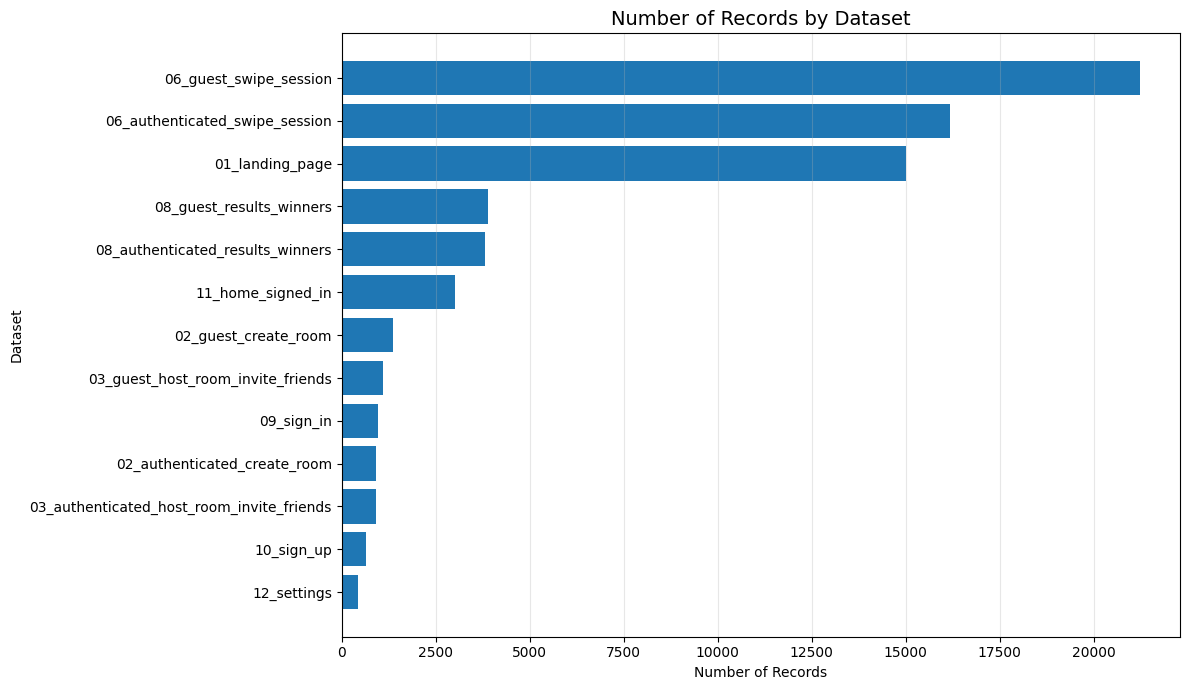

In [4]:
# Візуалізуємо кількість записів у кожному датасеті

plot_data = overview_df.sort_values("rows", ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    plot_data["dataset"],
    plot_data["rows"]
)

ax.set_title("Number of Records by Dataset", fontsize=14)
ax.set_xlabel("Number of Records")
ax.set_ylabel("Dataset")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Формуємо набір фактичних подій

# Нормалізуємо Boolean-значення

all_events["event_value_bool"] = (
    all_events["event_value"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
    .astype("boolean")
)

# Визначаємо Boolean-записи

is_boolean = (
    all_events["event_value_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("boolean")
)

# Залишаємо фактичні події:
# Boolean True та всі записи з іншими типами значень

activity_df = all_events[
    (~is_boolean) | (all_events["event_value_bool"] == True)
].copy()

# Виводимо результати фільтрації

print(f"Усі записи: {len(all_events):,}")
print(f"Фактичні події: {len(activity_df):,}")
print(f"Відфільтровано Boolean False/пропущених значень: {len(all_events) - len(activity_df):,}")

# Аналізуємо кількість подій

event_distribution = (
    activity_df
    .groupby(["dataset", "event_name"])
    .agg(
        total_records=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
)

# Визначаємо найпоширеніші події

event_totals = (
    activity_df["event_name"]
    .value_counts()
    .rename_axis("event_name")
    .reset_index(name="total_records")
)

display(event_totals.head(20))

Усі записи: 69,431
Фактичні події: 47,657
Відфільтровано Boolean False/пропущених значень: 21,774


,event_name,total_records
0,movie_liked,7995
1,swipe_right,7628
2,movie_disliked,6705
3,swipe_left,6309
4,Like_button,2883
5,dislike_button,2480
6,movie_won,1881
7,swipe_session_started,1700
8,swipe_session_completed,1700
9,join_room_clicked,1176


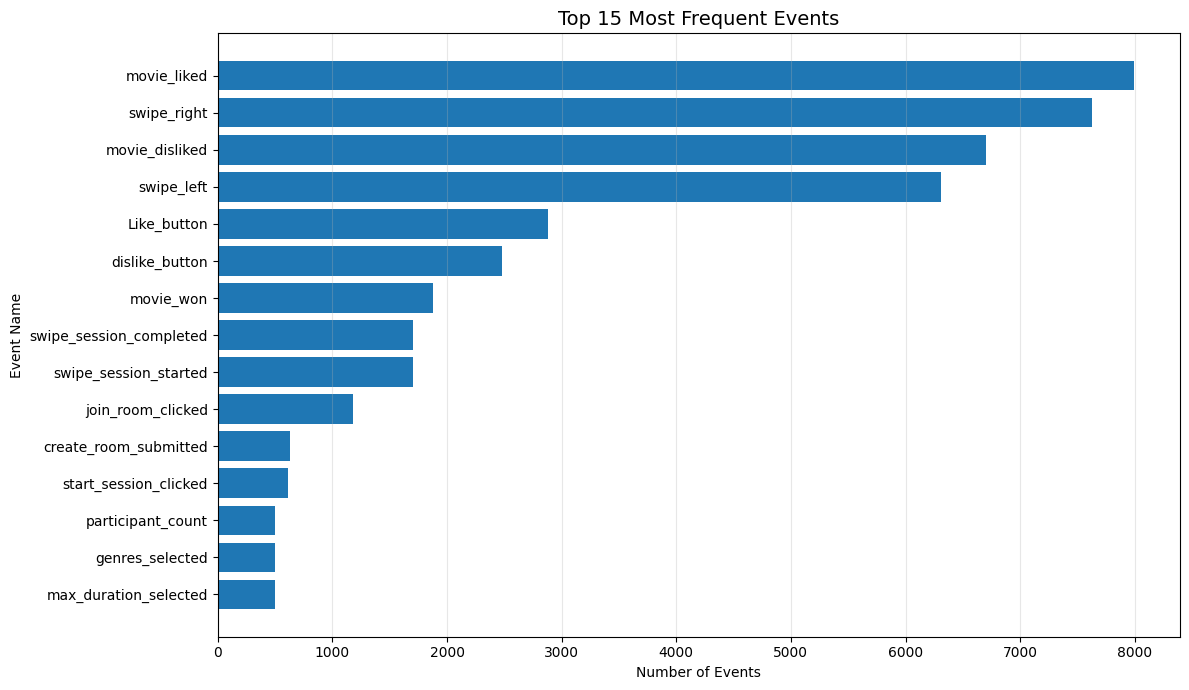

In [6]:
# Візуалізуємо 15 найпоширеніших подій

top_events = event_totals.head(15).sort_values(
    "total_records",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_events["event_name"],
    top_events["total_records"]
)

ax.set_title("Top 15 Most Frequent Events", fontsize=14)
ax.set_xlabel("Number of Events")
ax.set_ylabel("Event Name")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

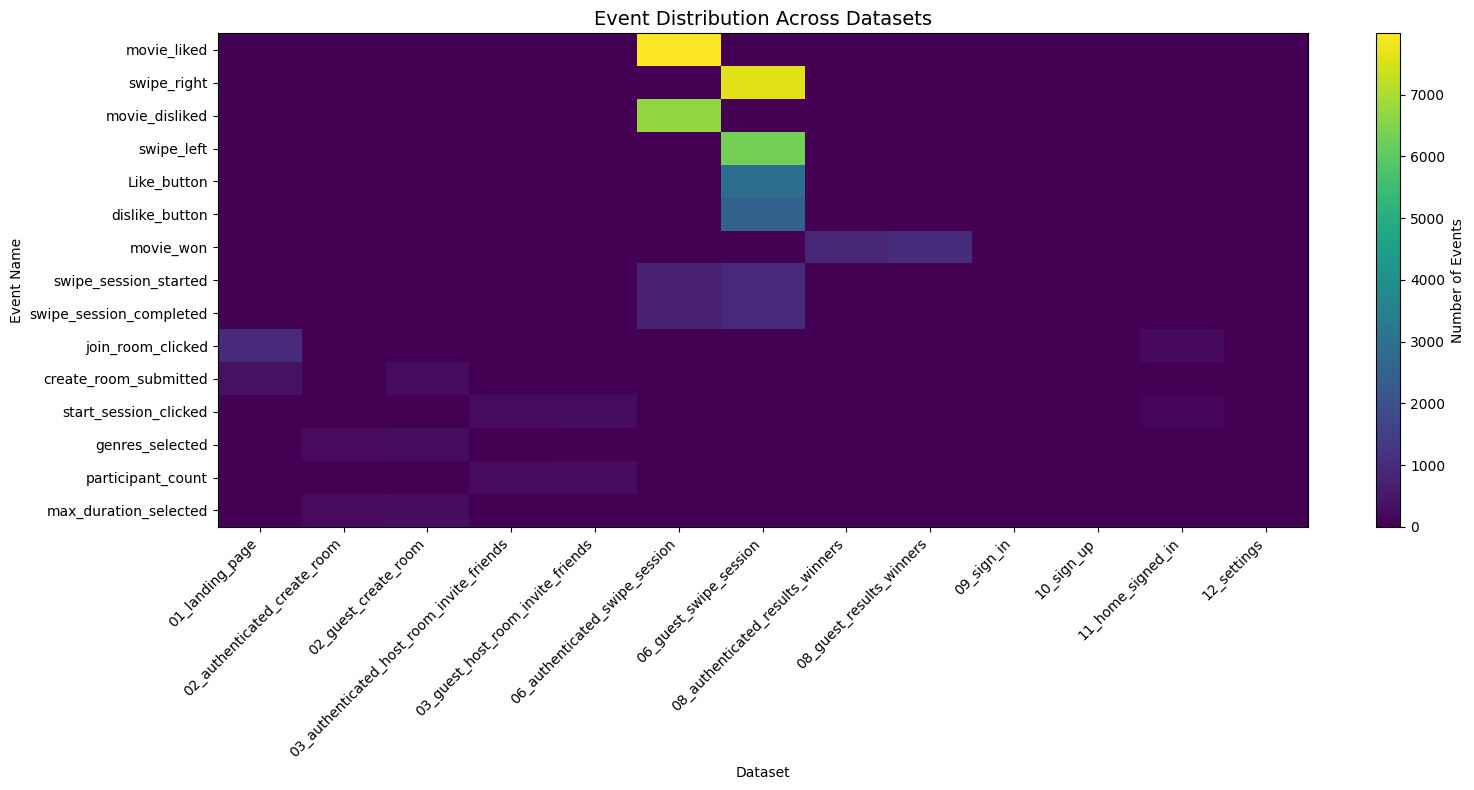

In [7]:
# Готуємо матрицю розподілу подій за датасетами

top_event_names = event_totals.head(15)["event_name"]

event_heatmap = (
    event_distribution
    .pivot(
        index="event_name",
        columns="dataset",
        values="total_records"
    )
    .reindex(top_event_names)
    .fillna(0)
)

# Візуалізуємо розподіл за допомогою теплової карти

fig, ax = plt.subplots(figsize=(16, 8))

image = ax.imshow(
    event_heatmap.values,
    aspect="auto"
)

ax.set_xticks(range(len(event_heatmap.columns)))
ax.set_xticklabels(
    event_heatmap.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(range(len(event_heatmap.index)))
ax.set_yticklabels(event_heatmap.index)

ax.set_title("Event Distribution Across Datasets", fontsize=14)
ax.set_xlabel("Dataset")
ax.set_ylabel("Event Name")

fig.colorbar(
    image,
    ax=ax,
    label="Number of Events"
)

plt.tight_layout()
plt.show()

In [8]:
# Відбираємо Boolean-події

boolean_events = all_events[
    is_boolean
].copy()

# Розраховуємо кількість True, False та некоректних значень

boolean_distribution = (
    boolean_events
    .groupby(["dataset", "event_name"])
    .agg(
        total_records=("event_id", "count"),
        true_count=(
            "event_value_bool",
            lambda x: x.eq(True).sum()
        ),
        false_count=(
            "event_value_bool",
            lambda x: x.eq(False).sum()
        ),
        invalid_values=(
            "event_value_bool",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# Розраховуємо частку True серед валідних Boolean-значень

boolean_distribution["valid_values"] = (
    boolean_distribution["true_count"]
    + boolean_distribution["false_count"]
)

boolean_distribution["true_rate_pct"] = (
    boolean_distribution["true_count"]
    .div(boolean_distribution["valid_values"].replace(0, pd.NA))
    * 100
)

display(
    boolean_distribution
    .sort_values("total_records", ascending=False)
    .round(2)
)

,dataset,event_name,total_records,true_count,false_count,invalid_values,valid_values,true_rate_pct
0,01_landing_page,account_section_sign_in_clicked,2500,90,2410,False,2500,3.60
1,01_landing_page,create_room_submitted,2500,352,2148,False,2500,14.08
2,01_landing_page,guest_start_clicked,2500,452,2048,False,2500,18.08
3,01_landing_page,header_sign_in_clicked,2500,106,2394,False,2500,4.24
4,01_landing_page,join_room_clicked,2500,963,1537,False,2500,38.52
5,01_landing_page,sign_up_clicked,2500,120,2380,False,2500,4.80
18,08_guest_results_winners,another_round_clicked,965,80,885,False,965,8.29
20,08_guest_results_winners,winner_details_clicked,965,219,746,False,965,22.69
19,08_guest_results_winners,sign_up_clicked,965,90,875,False,965,9.33
14,08_authenticated_results_winners,another_round_clicked,735,78,657,False,735,10.61


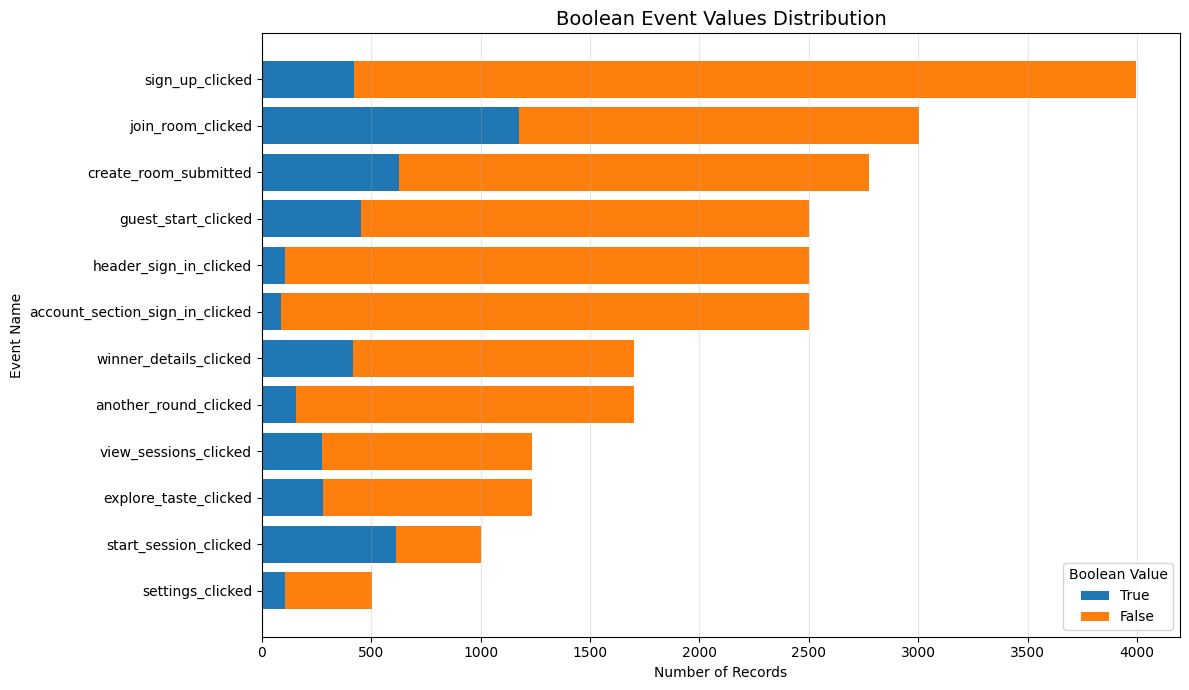

In [9]:
# Формуємо загальну статистику Boolean-подій

boolean_chart_data = (
    boolean_distribution
    .groupby("event_name")[
        ["true_count", "false_count"]
    ]
    .sum()
)

boolean_chart_data["total"] = (
    boolean_chart_data["true_count"]
    + boolean_chart_data["false_count"]
)

boolean_chart_data = (
    boolean_chart_data
    .sort_values("total", ascending=False)
    .head(12)
    .sort_values("total", ascending=True)
)

# Візуалізуємо розподіл True та False

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    boolean_chart_data.index,
    boolean_chart_data["true_count"],
    label="True"
)

ax.barh(
    boolean_chart_data.index,
    boolean_chart_data["false_count"],
    left=boolean_chart_data["true_count"],
    label="False"
)

ax.set_title("Boolean Event Values Distribution", fontsize=14)
ax.set_xlabel("Number of Records")
ax.set_ylabel("Event Name")
ax.legend(title="Boolean Value")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Нормалізуємо типи користувачів

activity_df["user_type_label"] = (
    activity_df["user_type"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
)

# Аналізуємо активність користувачів за їхнім типом

user_activity = (
    activity_df
    .groupby("user_type_label")
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique"),
        active_page_views=("page_view_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо середню кількість подій на одного відвідувача

user_activity["avg_events_per_visitor"] = (
    user_activity["total_events"]
    / user_activity["unique_visitors"].replace(0, pd.NA)
)

# Розраховуємо частку подій кожного сегмента

user_activity["events_share_pct"] = (
    user_activity["total_events"]
    / user_activity["total_events"].sum()
    * 100
)

display(
    user_activity
    .sort_values("total_events", ascending=False)
    .round(2)
)

,user_type_label,total_events,unique_visitors,unique_users,active_page_views,avg_events_per_visitor,events_share_pct
2,GUEST,25453,965,0,2686,26.38,53.41
1,AUTHENTICATED,20907,522,543,2860,40.05,43.87
0,ANONYMOUS,1297,1162,0,1234,1.12,2.72


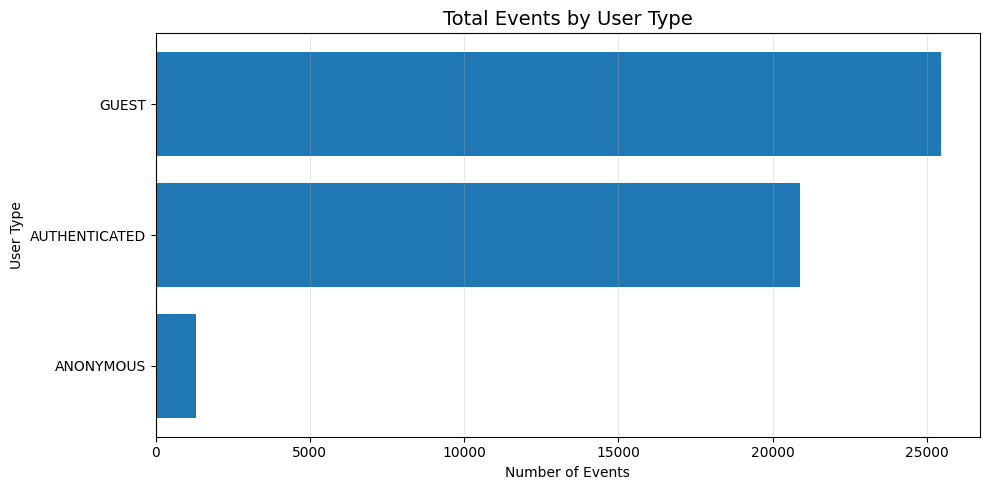

In [11]:
# Візуалізуємо активність за типами користувачів

user_plot = user_activity.sort_values(
    "total_events",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    user_plot["user_type_label"],
    user_plot["total_events"]
)

ax.set_title("Total Events by User Type", fontsize=14)
ax.set_xlabel("Number of Events")
ax.set_ylabel("User Type")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# Розраховуємо кількість подій для кожного відвідувача

visitor_activity = (
    activity_df[
        activity_df["visitor_id"].notna()
    ]
    .groupby(["user_type_label", "visitor_id"])
    .agg(
        total_events=("event_id", "count")
    )
    .reset_index()
)

# Формуємо статистику активності відвідувачів

activity_distribution = (
    visitor_activity
    .groupby("user_type_label")
    .agg(
        visitors=("visitor_id", "count"),
        mean=("total_events", "mean"),
        median=("total_events", "median"),
        min=("total_events", "min"),
        q25=("total_events", lambda x: x.quantile(0.25)),
        q75=("total_events", lambda x: x.quantile(0.75)),
        max=("total_events", "max")
    )
    .reset_index()
)

display(activity_distribution.round(2))

,user_type_label,visitors,mean,median,min,q25,q75,max
0,ANONYMOUS,1162,1.12,1.0,1,1.0,1.0,5
1,AUTHENTICATED,522,40.05,30.5,2,3.0,60.0,185
2,GUEST,965,26.38,23.0,22,23.0,32.0,43


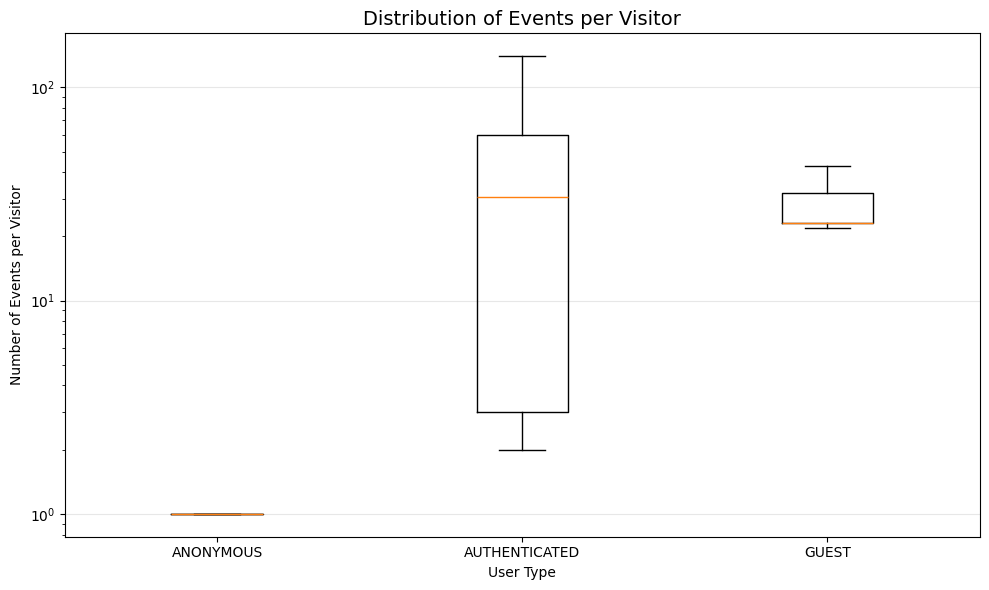

In [13]:
# Формуємо дані для побудови Boxplot

user_types_order = sorted(
    visitor_activity["user_type_label"].dropna().unique()
)

boxplot_data = [
    visitor_activity.loc[
        visitor_activity["user_type_label"] == user_type,
        "total_events"
    ].values
    for user_type in user_types_order
]

# Візуалізуємо розподіл активності

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    boxplot_data,
    showfliers=False
)

ax.set_xticks(range(1, len(user_types_order) + 1))
ax.set_xticklabels(user_types_order)

ax.set_title("Distribution of Events per Visitor", fontsize=14)
ax.set_xlabel("User Type")
ax.set_ylabel("Number of Events per Visitor")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# Готуємо часові дані для аналізу

temporal_df = activity_df[
    activity_df["event_timestamp"].notna()
].copy()

# Виділяємо дату та годину події

temporal_df["event_date"] = (
    temporal_df["event_timestamp"].dt.floor("D")
)

temporal_df["event_hour"] = (
    temporal_df["event_timestamp"].dt.hour
)

# Перевіряємо часовий діапазон

print("Кількість записів:", len(temporal_df))
print(
    "Записів без коректного timestamp:",
    activity_df["event_timestamp"].isna().sum()
)
print("Початок періоду:", temporal_df["event_timestamp"].min())
print("Кінець періоду:", temporal_df["event_timestamp"].max())

# Визначаємо повний календарний діапазон

first_date = temporal_df["event_date"].min()
last_date = temporal_df["event_date"].max()

calendar_days = pd.date_range(
    start=first_date,
    end=last_date,
    freq="D"
)

user_types = sorted(
    temporal_df["user_type_label"].dropna().unique()
)

# Розраховуємо щоденну активність

daily_counts = (
    temporal_df
    .groupby(["event_date", "user_type_label"])
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique")
    )
)

# Додаємо календарні дні без подій

full_index = pd.MultiIndex.from_product(
    [calendar_days, user_types],
    names=["event_date", "user_type_label"]
)

daily_activity = (
    daily_counts
    .reindex(full_index, fill_value=0)
    .reset_index()
)

# Перевіряємо результат

print("Кількість календарних днів:", len(calendar_days))
print("Днів без подій:", (
    daily_activity
    .groupby("event_date")["total_events"]
    .sum()
    .eq(0)
    .sum()
))

display(daily_activity.head(10))

Кількість записів: 47657
Записів без коректного timestamp: 0
Початок періоду: 2026-09-01 07:24:58+00:00
Кінець періоду: 2026-11-11 22:19:08+00:00
Кількість календарних днів: 72
Днів без подій: 0


,event_date,user_type_label,total_events,unique_visitors,unique_users
0,2026-09-01 00:00:00+00:00,ANONYMOUS,17,17,0
1,2026-09-01 00:00:00+00:00,AUTHENTICATED,241,31,31
2,2026-09-01 00:00:00+00:00,GUEST,215,15,0
3,2026-09-02 00:00:00+00:00,ANONYMOUS,13,13,0
4,2026-09-02 00:00:00+00:00,AUTHENTICATED,374,22,22
5,2026-09-02 00:00:00+00:00,GUEST,499,30,0
6,2026-09-03 00:00:00+00:00,ANONYMOUS,28,27,0
7,2026-09-03 00:00:00+00:00,AUTHENTICATED,235,20,20
8,2026-09-03 00:00:00+00:00,GUEST,402,22,0
9,2026-09-04 00:00:00+00:00,ANONYMOUS,20,20,0


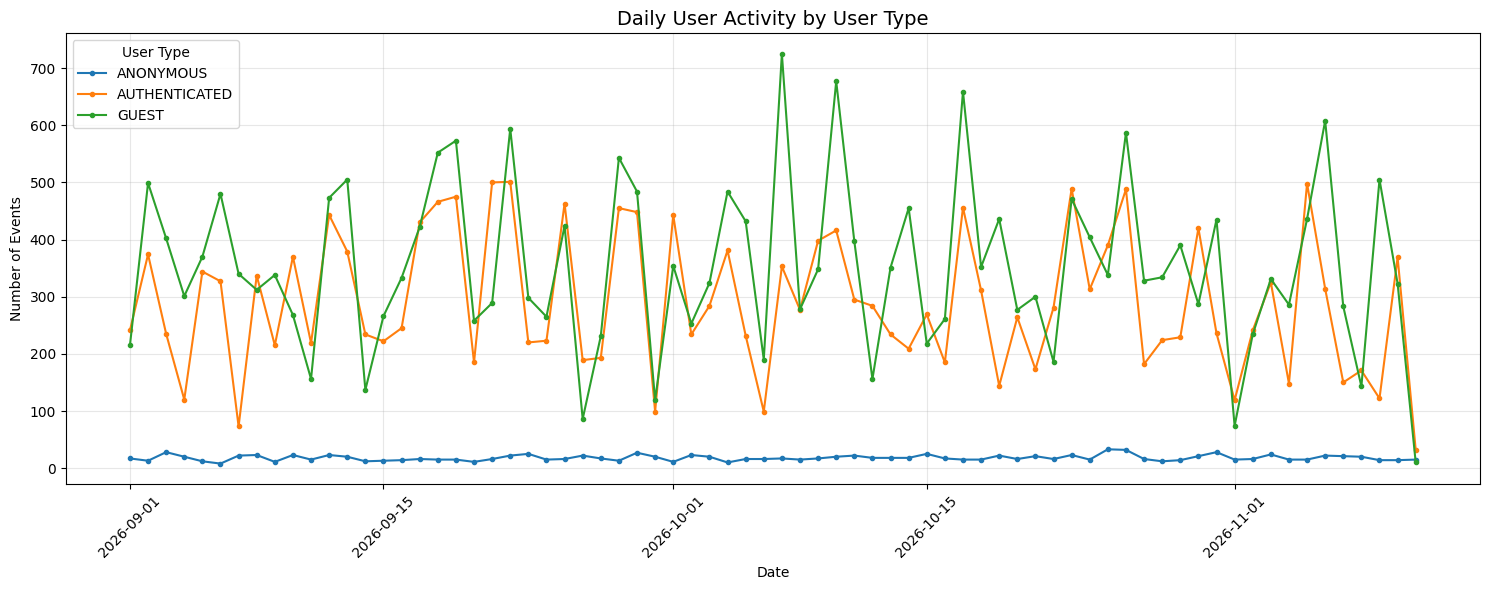

In [15]:
# Формуємо таблицю щоденної активності

daily_pivot = (
    daily_activity
    .pivot(
        index="event_date",
        columns="user_type_label",
        values="total_events"
    )
    .fillna(0)
)

# Додаємо загальну кількість подій

daily_pivot["TOTAL"] = daily_pivot.sum(axis=1)

# Візуалізуємо динаміку активності

fig, ax = plt.subplots(figsize=(15, 6))

for user_type in user_types:

    ax.plot(
        daily_pivot.index,
        daily_pivot[user_type],
        marker="o",
        markersize=3,
        label=user_type
    )

ax.set_title("Daily User Activity by User Type", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Number of Events")
ax.legend(title="User Type")
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Визначаємо повні календарні дні для порівняння

full_days = calendar_days[
    (calendar_days > first_date)
    & (calendar_days < last_date)
]

if len(full_days) == 0:

    reference_days = calendar_days

    print(
        "У періоді немає повних проміжних днів. "
        "Для аналізу використовуються всі доступні дні."
    )

else:

    reference_days = full_days

    print(
        f"Для аналізу використовується "
        f"{len(reference_days)} повних календарних днів."
    )

# Залишаємо дані за вибрані календарні дні

temporal_full_days = temporal_df[
    temporal_df["event_date"].isin(reference_days)
].copy()

# Розраховуємо погодинну активність

hourly_counts = (
    temporal_full_days
    .groupby(["event_hour", "user_type_label"])
    .agg(
        total_events=("event_id", "count")
    )
)

# Створюємо повну сітку годин та типів користувачів

hourly_index = pd.MultiIndex.from_product(
    [range(24), user_types],
    names=["event_hour", "user_type_label"]
)

hourly_summary = (
    hourly_counts
    .reindex(hourly_index, fill_value=0)
    .reset_index()
)

# Розраховуємо середню кількість подій за годину на день

hourly_summary["avg_events_per_day"] = (
    hourly_summary["total_events"] / len(reference_days)
)

display(hourly_summary.round(2))

Для аналізу використовується 70 повних календарних днів.


,event_hour,user_type_label,total_events,avg_events_per_day
0,0,ANONYMOUS,0,0.00
1,0,AUTHENTICATED,0,0.00
2,0,GUEST,0,0.00
3,1,ANONYMOUS,0,0.00
4,1,AUTHENTICATED,0,0.00
...,...,...,...,...
67,22,AUTHENTICATED,55,0.79
68,22,GUEST,0,0.00
69,23,ANONYMOUS,0,0.00
70,23,AUTHENTICATED,0,0.00


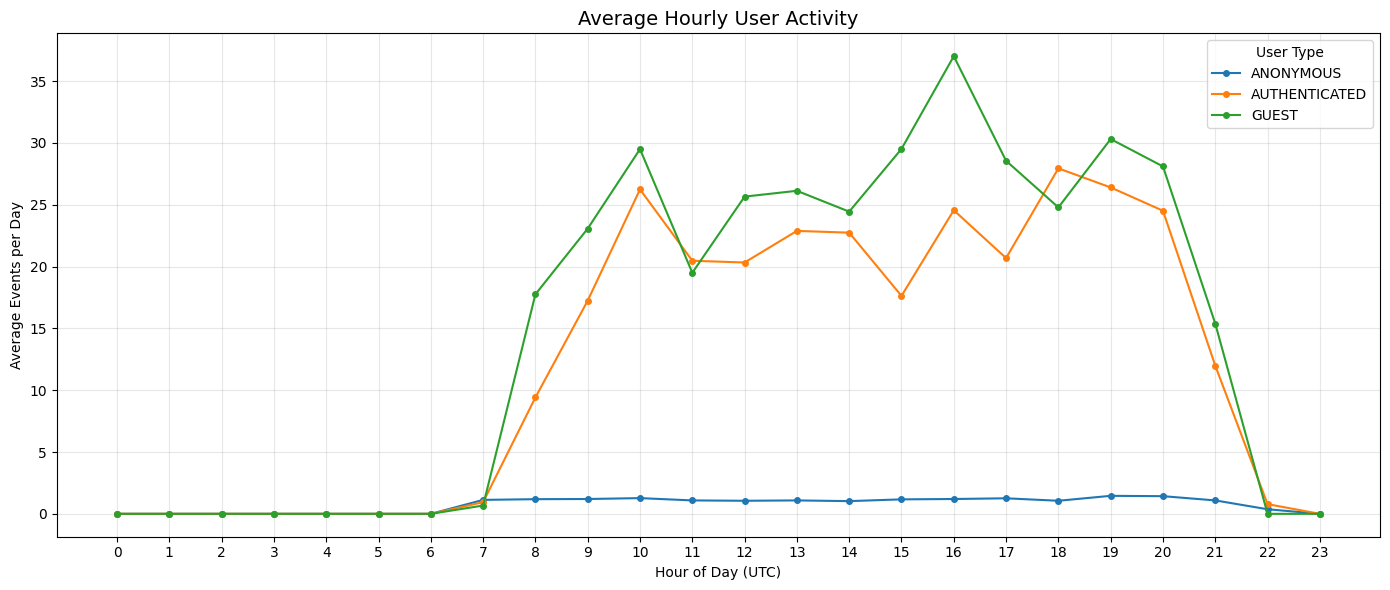

In [17]:
# Формуємо таблицю для погодинного графіка

hourly_pivot = (
    hourly_summary
    .pivot(
        index="event_hour",
        columns="user_type_label",
        values="avg_events_per_day"
    )
    .reindex(range(24))
    .fillna(0)
)

# Візуалізуємо середню погодинну активність

fig, ax = plt.subplots(figsize=(14, 6))

for user_type in user_types:

    ax.plot(
        hourly_pivot.index,
        hourly_pivot[user_type],
        marker="o",
        markersize=4,
        label=user_type
    )

ax.set_title("Average Hourly User Activity", fontsize=14)
ax.set_xlabel("Hour of Day (UTC)")
ax.set_ylabel("Average Events per Day")
ax.set_xticks(range(24))
ax.legend(title="User Type")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# Додаємо назви днів тижня

weekday_activity = daily_activity[
    daily_activity["event_date"].isin(reference_days)
].copy()

weekday_activity["weekday"] = (
    weekday_activity["event_date"].dt.day_name()
)

# Визначаємо порядок днів тижня

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# Розраховуємо середню кількість подій за кожен день тижня

weekday_summary = (
    weekday_activity
    .groupby(["weekday", "user_type_label"])
    .agg(
        avg_events_per_day=("total_events", "mean"),
        median_events_per_day=("total_events", "median"),
        days_observed=("event_date", "nunique")
    )
    .reset_index()
)

# Формуємо таблицю для візуалізації

weekday_pivot = (
    weekday_summary
    .pivot(
        index="weekday",
        columns="user_type_label",
        values="avg_events_per_day"
    )
    .reindex(weekday_order)
    .fillna(0)
)

display(weekday_summary.round(2))

,weekday,user_type_label,avg_events_per_day,median_events_per_day,days_observed
0,Friday,ANONYMOUS,18.9,18.5,10
1,Friday,AUTHENTICATED,330.8,356.0,10
2,Friday,GUEST,366.1,324.5,10
3,Monday,ANONYMOUS,18.1,16.0,10
4,Monday,AUTHENTICATED,277.3,237.5,10
5,Monday,GUEST,365.9,386.0,10
6,Saturday,ANONYMOUS,19.1,20.0,10
7,Saturday,AUTHENTICATED,330.6,328.5,10
8,Saturday,GUEST,428.4,419.5,10
9,Sunday,ANONYMOUS,17.1,16.0,10


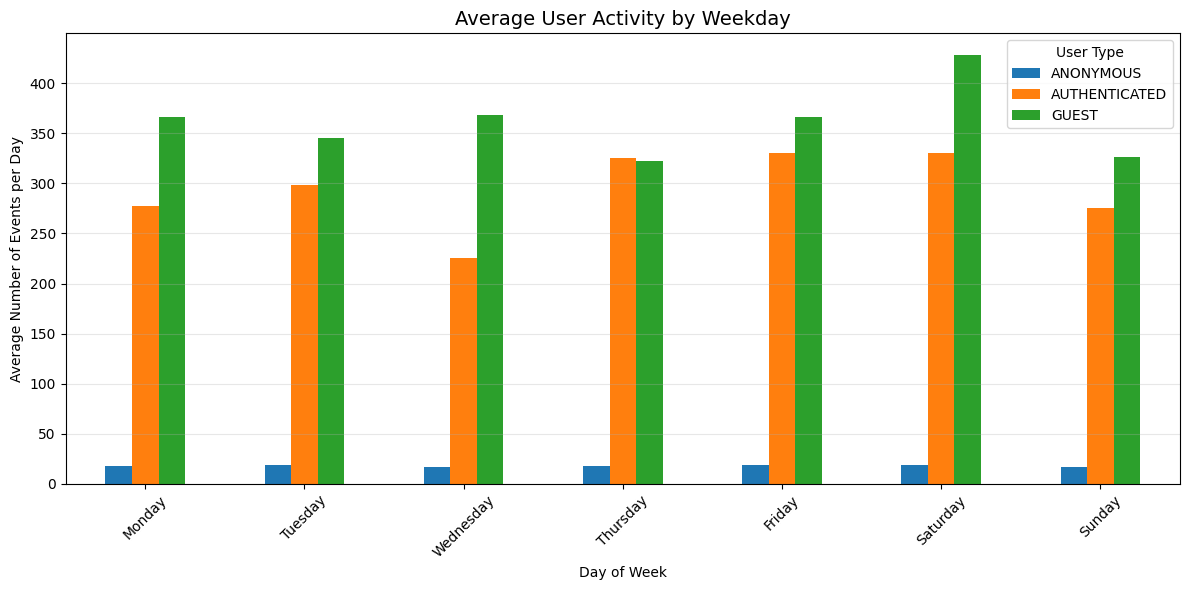

In [19]:
# Візуалізуємо середню активність за днями тижня

fig, ax = plt.subplots(figsize=(12, 6))

weekday_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Average User Activity by Weekday", fontsize=14)
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average Number of Events per Day")
ax.legend(title="User Type")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Аналізуємо активність користувачів на кожній сторінці

page_activity = (
    activity_df
    .groupby("dataset")
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique"),
        unique_users=("user_id", "nunique"),
        page_views=("page_view_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо середню кількість подій на відвідувача

page_activity["avg_events_per_visitor"] = (
    page_activity["total_events"]
    / page_activity["unique_visitors"].replace(0, pd.NA)
)

# Розраховуємо середню кількість подій на перегляд сторінки

page_activity["avg_events_per_page_view"] = (
    page_activity["total_events"]
    / page_activity["page_views"].replace(0, pd.NA)
)

# Розраховуємо частку подій кожної сторінки

page_activity["events_share_pct"] = (
    page_activity["total_events"]
    / page_activity["total_events"].sum()
    * 100
)

# Сортуємо сторінки за кількістю подій

page_activity = page_activity.sort_values(
    "total_events",
    ascending=False
).reset_index(drop=True)

display(page_activity.round(2))

,dataset,total_events,unique_visitors,unique_users,page_views,avg_events_per_visitor,avg_events_per_page_view,events_share_pct
0,06_guest_swipe_session,21230,965,0,965,22.00,22.00,44.55
1,06_authenticated_swipe_session,16170,373,373,735,43.35,22.00,33.93
2,01_landing_page,2083,1679,312,2083,1.24,1.00,4.37
3,08_authenticated_results_winners,1475,323,323,530,4.57,2.78,3.10
4,08_guest_results_winners,1397,514,0,514,2.72,2.72,2.93
5,02_guest_create_room,1375,275,0,275,5.00,5.00,2.89
6,02_authenticated_create_room,900,177,177,225,5.08,4.00,1.89
7,11_home_signed_in,822,363,381,443,2.26,1.86,1.72
8,03_guest_host_room_invite_friends,794,275,0,275,2.89,2.89,1.67
9,03_authenticated_host_room_invite_friends,666,177,177,225,3.76,2.96,1.40


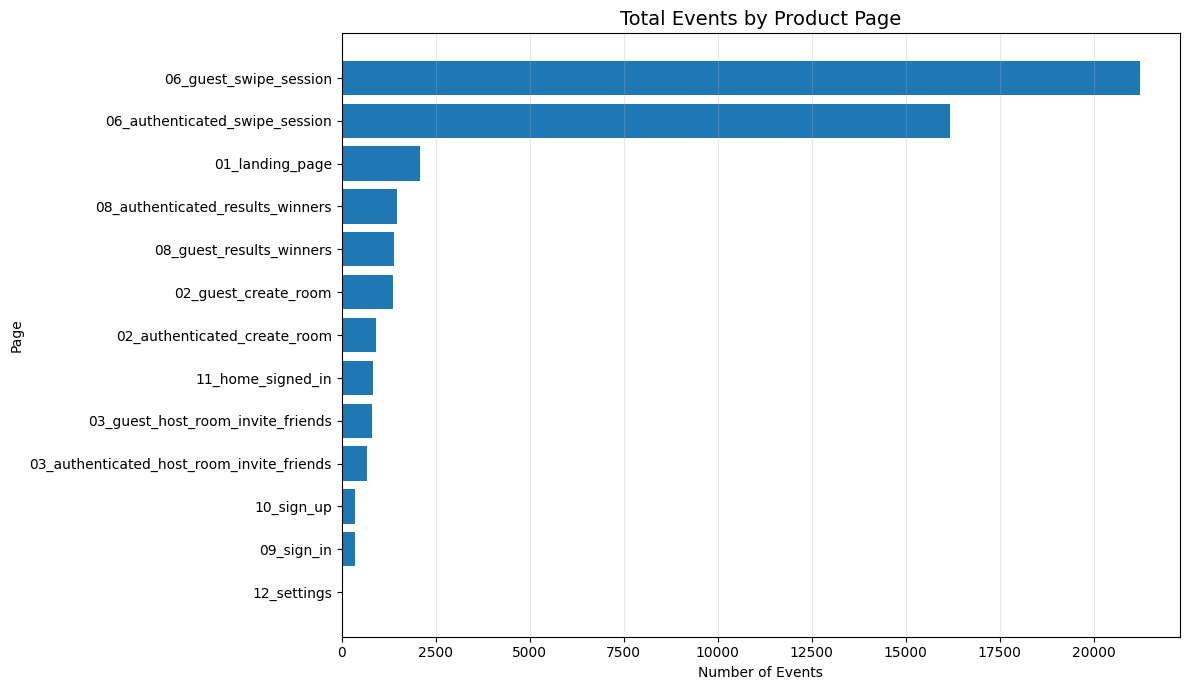

In [21]:
# Візуалізуємо кількість фактичних подій за сторінками

page_plot = page_activity.sort_values(
    "total_events",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    page_plot["dataset"],
    page_plot["total_events"]
)

ax.set_title("Total Events by Product Page", fontsize=14)
ax.set_xlabel("Number of Events")
ax.set_ylabel("Page")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

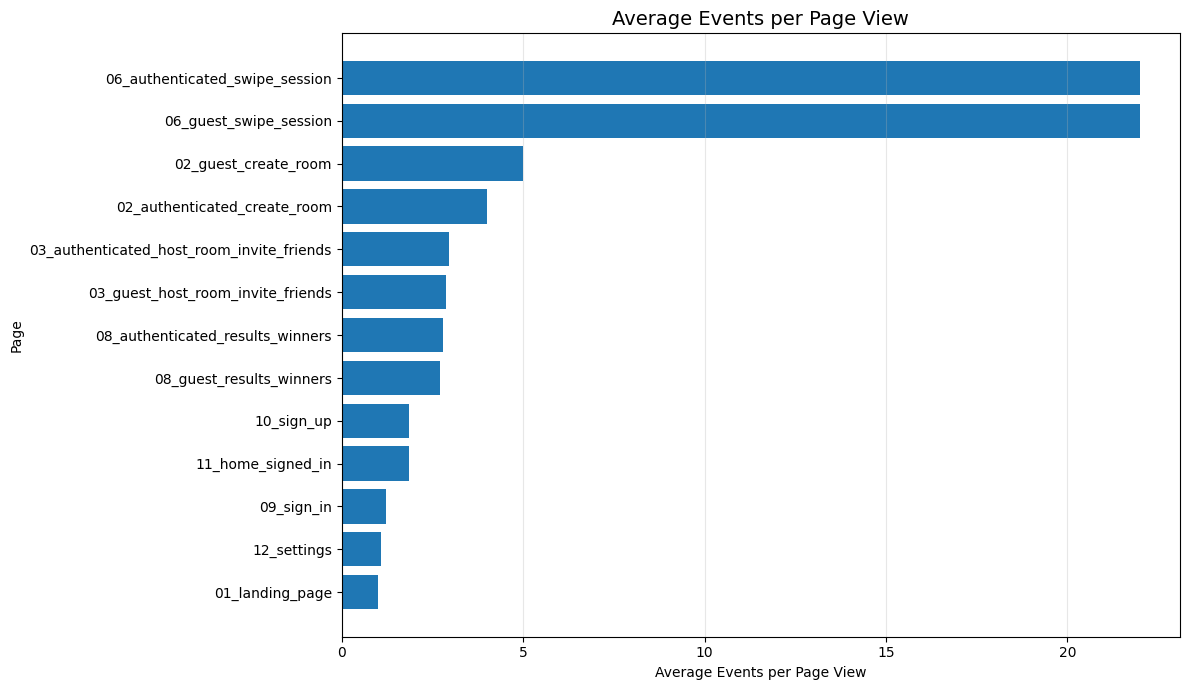

In [22]:
# Візуалізуємо середню кількість подій на перегляд сторінки

page_intensity = (
    page_activity
    .dropna(subset=["avg_events_per_page_view"])
    .sort_values("avg_events_per_page_view", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    page_intensity["dataset"],
    page_intensity["avg_events_per_page_view"]
)

ax.set_title("Average Events per Page View", fontsize=14)
ax.set_xlabel("Average Events per Page View")
ax.set_ylabel("Page")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Аналізуємо розподіл подій усередині кожної сторінки

page_event_distribution = (
    activity_df
    .groupby(["dataset", "event_name"])
    .agg(
        event_count=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо загальну кількість подій на кожній сторінці

page_event_distribution["page_total_events"] = (
    page_event_distribution
    .groupby("dataset")["event_count"]
    .transform("sum")
)

# Розраховуємо частку кожної події всередині сторінки

page_event_distribution["event_share_pct"] = (
    page_event_distribution["event_count"]
    / page_event_distribution["page_total_events"]
    * 100
)

# Додаємо загальну кількість відвідувачів сторінки

page_event_reach = page_event_distribution.merge(
    page_activity[
        ["dataset", "unique_visitors"]
    ].rename(
        columns={"unique_visitors": "page_unique_visitors"}
    ),
    on="dataset",
    how="left"
)

# Розраховуємо охоплення події відвідувачами сторінки

page_event_reach["visitor_reach_pct"] = (
    page_event_reach["unique_visitors"]
    / page_event_reach["page_unique_visitors"].replace(0, pd.NA)
    * 100
)

# Розраховуємо кількість повторень події на одного відвідувача

page_event_reach["events_per_visitor"] = (
    page_event_reach["event_count"]
    / page_event_reach["unique_visitors"].replace(0, pd.NA)
)

# Формуємо таблицю найпоширеніших подій за охопленням

top_page_event_reach = (
    page_event_reach
    .sort_values("visitor_reach_pct", ascending=False)
    .head(20)
)

display(
    top_page_event_reach[
        [
            "dataset",
            "event_name",
            "event_count",
            "unique_visitors",
            "page_unique_visitors",
            "visitor_reach_pct",
            "events_per_visitor"
        ]
    ].round(2)
)

,dataset,event_name,event_count,unique_visitors,page_unique_visitors,visitor_reach_pct,events_per_visitor
7,02_authenticated_create_room,create_room_clicked,225,177,177,100.0,1.27
6,02_authenticated_create_room,content_type_selected,225,177,177,100.0,1.27
8,02_authenticated_create_room,genres_selected,225,177,177,100.0,1.27
14,02_guest_create_room,max_duration_selected,275,275,275,100.0,1.00
13,02_guest_create_room,guest_name_entered,275,275,275,100.0,1.00
12,02_guest_create_room,genres_selected,275,275,275,100.0,1.00
11,02_guest_create_room,create_room_submitted,275,275,275,100.0,1.00
10,02_guest_create_room,content_type_selected,275,275,275,100.0,1.00
9,02_authenticated_create_room,max_duration_selected,225,177,177,100.0,1.27
23,06_authenticated_swipe_session,movie_disliked,6705,373,373,100.0,17.98


### Висновки за результатами дослідницького аналізу даних (EDA)

У межах дослідницького аналізу було розглянуто 13 датасетів проєкту Movie Match, які містять загалом **69 431 запис** та 29 колонок кожен. Дані охоплюють період з 1 вересня до 11 листопада 2026 року. Загалом було виявлено **38 унікальних типів подій**, що відображають взаємодію користувачів із різними етапами продукту.

**1. Структура та розподіл даних**

Найбільшу кількість записів містять датасети, пов'язані з процесом голосування:

- `06_guest_swipe_session` — 21 230 записів;
- `06_authenticated_swipe_session` — 16 170 записів;
- `01_landing_page` — 15 000 записів.

На ці три датасети припадає приблизно 75,5% усіх початкових записів. Такий розподіл свідчить про значну представленість процесів взаємодії з фільмами та початкової сторінки в досліджуваному наборі даних.

Водночас кількість записів не завжди відображає фактичну активність користувачів, оскільки частина подій має Boolean-значення `False`, які відповідають невиконаним діям.

**2. Розподіл подій та основні користувацькі взаємодії**

Після відокремлення фактичних подій за прийнятою логікою фільтрації було отримано **47 657 записів**. Із загального обсягу виключено 21 774 Boolean-записи зі значеннями, що не відповідають фактичному виконанню дії.

Найпоширенішими типами подій виявилися:

- `movie_liked` — 7 995 записів;
- `swipe_right` — 7 628 записів;
- `movie_disliked` — 6 705 записів;
- `swipe_left` — 6 309 записів;
- `Like_button` — 2 883 записи;
- `dislike_button` — 2 480 записів.

Шість зазначених типів подій, пов'язаних із позитивним та негативним оцінюванням фільмів, разом становлять 34 000 записів. Це приблизно 71,3% усіх фактичних подій.

Отже, основний обсяг зафіксованої взаємодії в досліджуваних даних зосереджений навколо механіки оцінювання фільмів за допомогою лайків, дизлайків та свайпів.

Також зафіксовано по 1 700 подій `swipe_session_started` та `swipe_session_completed`, а кількість подій `movie_won` становить 1 881 запис.

**3. Аналіз Boolean-подій**

Аналіз Boolean-полів дозволив оцінити розподіл виконаних та невиконаних дій у різних частинах продукту.

На Landing Page найбільшу частку значень `True` серед окремих взаємодій має подія `join_room_clicked` — 38,52%. Для `guest_start_clicked` цей показник становить 18,08%, а для `create_room_submitted` — 14,08%.

На сторінці авторизованого користувача `11_home_signed_in` частка `True` для `join_room_clicked` становить 42,43%, а для `session_details_clicked` — 30,48%.

На сторінках створення кімнати та запуску сесії ключові події `create_room_submitted`, `create_room_clicked` і `start_session_clicked` мають 100% значень `True` у відповідних датасетах.

Ці результати характеризують розподіл значень Boolean-полів, але самі по собі не є показниками конверсії користувачів. Для коректної оцінки конверсії необхідно окремо зіставляти користувачів або кімнати між послідовними етапами продуктового сценарію.

**4. Порівняння активності різних типів користувачів**

За кількістю фактичних подій найбільшу активність демонструє сегмент `GUEST`:

- `GUEST` — 25 453 події (53,41%);
- `AUTHENTICATED` — 20 907 подій (43,87%);
- `ANONYMOUS` — 1 297 подій (2,72%).

Водночас середня кількість подій на одного відвідувача відрізняється між сегментами:

- `AUTHENTICATED` — 40,05 події;
- `GUEST` — 26,38 події;
- `ANONYMOUS` — 1,12 події.

Медіанне значення кількості подій на відвідувача також вище для авторизованих користувачів — 30,5 проти 23 у сегменті Guest. Для Anonymous медіана становить лише 1 подію.

Boxplot додатково демонструє значну варіативність активності авторизованих користувачів: у цьому сегменті спостерігаються як відвідувачі з невеликою кількістю подій, так і значно активніші користувачі. Активність гостей є більш компактно розподіленою, тоді як більшість анонімних відвідувачів мають лише одну зафіксовану подію.

Таким чином, хоча сегмент Guest генерує найбільшу загальну кількість подій, авторизовані користувачі демонструють вищу середню та медіанну інтенсивність взаємодії на одного відвідувача.

**5. Часовий аналіз активності**

Часовий аналіз охоплює 72 календарні дні — з 1 вересня до 11 листопада 2026 року. Усі 47 657 фактичних подій мають коректні часові мітки. У межах усього періоду не виявлено календарних днів без зафіксованої активності.

Щоденна динаміка демонструє помітні коливання активності сегментів Guest та Authenticated. Кількість подій Guest у більшості днів є вищою, хоча співвідношення між сегментами змінюється залежно від дати.

Аналіз середньої погодинної активності за 70 повними календарними днями показав, що основна взаємодія відбувається приблизно з 08:00 до 20:00 UTC.

Найвищі значення активності Guest спостерігаються близько 16:00 UTC, а Authenticated — переважно в діапазоні 18:00–19:00 UTC. У нічний час активність обох сегментів суттєво знижується.

За днями тижня найбільша середня активність Guest спостерігається в суботу — 428,4 події на день. Для Authenticated найвищі значення також зафіксовано в суботу — 330,6 події на день, хоча показники п'ятниці та четверга є близькими.

Ці результати вказують на відмінності в розподілі активності протягом доби та тижня, які надалі можуть бути використані для дослідження часу взаємодії користувачів із продуктом.

**6. Аналіз активності за сторінками продукту**

Найбільшу кількість фактичних подій зафіксовано на сторінках голосування:

- `06_guest_swipe_session` — 21 230 подій (44,55%);
- `06_authenticated_swipe_session` — 16 170 подій (33,93%).

Разом ці дві сторінки генерують приблизно 78,5% усіх фактичних подій.

Наступною за активністю є `01_landing_page` — 2 083 фактичні події (4,37%). Важливо, що початково цей датасет містив 15 000 записів, але значна їх частина мала Boolean-значення `False` і не враховувалася під час аналізу фактичних дій.

Порівняння середньої кількості подій на один перегляд сторінки показало найбільшу інтенсивність на сторінках голосування: приблизно 22 події на один перегляд як для Guest, так і для Authenticated.

Для сторінок створення кімнати цей показник становить близько 5 подій на перегляд, для сторінок запрошення друзів — приблизно 2,9–3,8, а для сторінок результатів — близько 2,7–4,6.

Отже, сторінки голосування є основною зоною взаємодії користувачів із продуктом за кількістю зафіксованих подій та інтенсивністю взаємодії.

**Загальний підсумок**

Проведений EDA дозволив визначити основні особливості поведінкових даних Movie Match:

- Найбільша частина зафіксованої активності пов'язана з процесом голосування та оцінювання фільмів.
- Сегмент Guest генерує найбільшу загальну кількість подій, тоді як Authenticated демонструє вищу середню інтенсивність взаємодії на одного відвідувача.
- Анонімні відвідувачі переважно мають мінімальну зафіксовану активність.
- Найбільша активність спостерігається в денні та вечірні години, а також у вихідні дні.
- Сторінки голосування формують основну частку фактичних подій продукту.
- Boolean-поля дозволяють відокремити зафіксовані виконані дії від невиконаних, але для оцінювання продуктової конверсії потрібен окремий аналіз послідовності користувацьких дій.

Результати EDA сформували загальне розуміння структури даних, основних користувацьких взаємодій та розподілу активності в продукті. Вони стали основою для наступних етапів дослідження: аналізу продуктових метрик, користувацьких сценаріїв і воронок, поведінки під час голосування та порівняння користувацьких сегментів.

Важливо враховувати, що набір даних є симульованим, тому виявлені закономірності характеризують саме досліджуваний датасет і не можуть автоматично узагальнюватися на реальну аудиторію продукту.